# 07 - Comparing runs 

In [1]:
import sys
sys.path.append("..")
import torch 
import matplotlib.pyplot as plt 
import numpy as np 
import json

In [2]:
with open('../results/run1_256/results.json', 'r') as f:
    results1 = json.load(f)
    cm1 = np.array(results1["min1"]["confusion_matrix"])
    # normalized rows give recall 
    normalized1 = cm1 / cm1.sum(axis=1, keepdims=True)

with open('../results/run2_weighted_256/results (1).json', 'r') as f:
    results2 = json.load(f)
    cm2 = np.array(results2["min1"]["confusion_matrix"])
    normalized2 = cm2 / cm2.sum(axis=1, keepdims=True)

# Comparing the two runs 
# big rock recall for run1 is 0.31
recall1 = normalized1[3, 3] 
recall2 = normalized2[3, 3]
precision1 =  cm1[3, 3] / cm1[:, 3].sum() 
precision2 = cm2[3, 3] / cm2[:, 3].sum()

# false alarms (FP)
# normalized[1, 3] (the share of bedrock pixels called big rock) and normalized[0, 3] (the same for soil), for both runs

# run1 for bedrock and soil 
bed1 = normalized1[1, 3] # bedrock predicted as big rock, run1
soil1 = normalized1[0, 3] # soil predicted as big rock, run1

# run2 for bedrock and soil
bed2 = normalized2[1, 3] # bedrock predicted as big rock, run2
soil2 = normalized2[0, 3] # soil predicted as big rock, run2

print(f"recall     run1 {recall1:.3f}  run2 {recall2:.3f}")
print(f"precision  run1 {precision1:.3f}  run2 {precision2:.3f}")
print(f"bedrock→BR run1 {bed1:.3f}  run2 {bed2:.3f}")
print(f"soil→BR    run1 {soil1:.3f}  run2 {soil2:.3f}")


recall     run1 0.315  run2 0.606
precision  run1 0.095  run2 0.093
bedrock→BR run1 0.015  run2 0.032
soil→BR    run1 0.000  run2 0.001


**Findings (min1, big rock):**

- Test IoU barely changed (.079 → .088), although val IoU rose (.29 → .465).
- Recall nearly doubled (.315 → .606); precision stayed at ~.09 in both runs.
- Bedrock pixels predicted as big rock doubled (1.5% → 3.2%). Because bedrock is far more common than big rock, these false positives outnumber the extra true positives.
- IoU is bounded by precision, so it stays flat.
- Weighting shifts errors from misses to false alarms. These are likely at rock edges and shadows (as in the 06 failure gallery). A possible cause of the val/test gap is that crowd labels mark big rock more generously than expert labels.

**Takeaway:** for hazard detection, a missed rock is worse than a false alarm, so run2's higher recall may be preferable despite equal IoU.

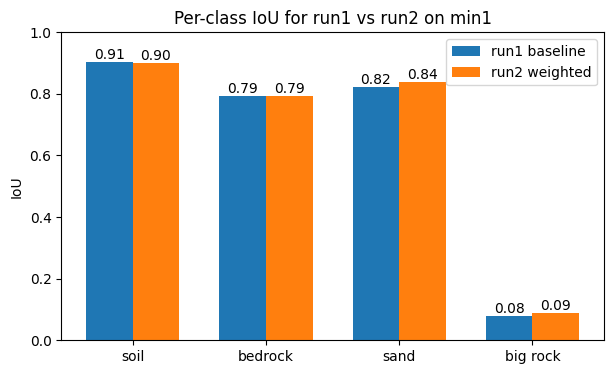

In [3]:
# per-class IoU for run1 vs run2 on min1
# 4 classes on the x-axis, two bars per class (run1, run2)

iou1 = results1["min1"]["iou"]
iou2 = results2["min1"]["iou"]
x = np.arange(4) # x positions 
w = 0.35 # bar width 

fig, ax = plt.subplots(figsize=(7, 4))
bars1 = ax.bar(x-w/2, iou1, w, label="run1 baseline")
bars2 = ax.bar(x+w/2, iou2, w, label="run2 weighted")


ax.set_xticks(x)
ax.set_xticklabels(["soil", "bedrock", "sand", "big rock"])
ax.set_ylabel("IoU")
ax.set_ylim(0, 1)
ax.set_title("Per-class IoU for run1 vs run2 on min1")
ax.legend()
ax.bar_label(bars1, fmt="%.2f")
ax.bar_label(bars2, fmt="%.2f")


plt.savefig("../results/compare_iou_min1.png", dpi=150, bbox_inches="tight")
plt.show()